# Thickness of cesium lead bromide nanoplatelets from high-throughput synthesis maps

> **Status: analysis outline.** Loading, the data checks, and the exploration run. The analysis sections give the plan in words, each followed by an empty code cell to fill in. Values marked `TO DECIDE` in Parameters are scientific choices still to be made and defended.

**Question.** Which precursor concentrations set the thickness of the cesium lead bromide nanoplatelets a synthesis makes, does a model that predicts the product survive a test on whole plates it has never seen, and how does the exciton energy depend on thickness?

**Data.** Dahl, J. C.; Wang, X.; Chan, E. M.; Alivisatos, A. P. Data from: High-throughput synthesis mapping of synthesis and transformation reactions of cesium lead bromide nanocrystals. Dryad, [doi:10.6078/D1XT4F](https://doi.org/10.6078/D1XT4F), accessed 2026-11-08. A liquid-handling robot mixed oleylamine (OLA), oleic acid (OA), lead oleate (Pb), and cesium oleate (Cs) solutions in dodecane in each well of 96-well plates and started the reaction by injecting benzoyl bromide (Br). Each product was diluted tenfold and its absorbance (250 to 700 nm) and emission (400 to 550 nm, excited at 350 nm) were read on a plate reader. The authors deconvoluted every absorbance spectrum into 12 reference spectra (1 to 4 monolayer (ML) nanoplatelets, bulk CsPbBr₃, and other Cs-Pb-Br species) plus scattering, and the file holds those fractions. `data/Metadata.pdf` describes each plate (Table 1) and each column (Table 2).

**Data and code availability.** `data/CsPbBr_synthesis.csv`, `data/CsPbBr_transformations.csv`, `data/Metadata.pdf`, and the authors' `data/Data Processing Notebook example.ipynb` are committed in `data/` as downloaded. This notebook reads only `CsPbBr_synthesis.csv`. The transformations file records a different experiment, in which reagents were added to finished products, and it does not bear on the question. All code is in this notebook, which runs from a restart in the environment that this repository's `uv.lock` rebuilds. Any random step uses the seeded generator in Parameters.

## Parameters

Every number that encodes a scientific choice is set here, with its unit and its reason. `TO DECIDE` marks a proposed value that the first analysis has to justify or replace.

In [2]:
import re
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn

DATA = Path("data")
SYNTH_FILE = DATA / "CsPbBr_synthesis.csv"  # the mapping experiments, one row per synthesis

CONC_COLS = ["[OLA]", "[Pb]", "[OA]", "[Cs]", "[Br]"]  # mM, reagent in the vial (Metadata.pdf Table 2)
VOLUME_COLS = ["Dodecane", "OLA", "Pb", "OA", "Cs", "Br"]  # uL of each solution added to the vial
NOMINAL_VOLUME = 500  # uL: every [X] in the file equals (stock mM) x (uL added) / 500, whatever the volumes add up to
VOLUME_TOLERANCE = 5  # uL: 1% of the nominal volume; nine p2 wells hold 502 to 504 uL, an error too small to matter
BR_DILUTION = {"p8": 10}  # plate: dilution of the Br solution; its Br column stores the undiluted-equivalent volume (Metadata.pdf Table 1)
WELLS_PER_PLATE = 96  # 8 rows (A to H) by 12 columns
STIR_RPM = {  # rpm, stir rate per plate from Metadata.pdf Table 1; it is not a column of the CSV
    "p0": 800, "p1": 600, "p2": 600, "p3": 600, "p4": 600, "p5": 400, "p6": 400, "p7": 400,
    "p8": 400, "p9": 400, "p10": 400, "p14": 400, "p15": 400, "p21": 400, "p22": 400,
}
REFERENCE_WELLS = ["p1G2", "p1C11", "p1D9", "p14A9", "p14G5", "p14B1", "p14E4",
                   "p9A1", "p2D5", "p4D11", "p15E2"]  # wells whose own spectra are deconvolution references in the authors' notebook (the 12th, p20B5, is a transformation well)

MIN_WAVELENGTH = 300  # nm: below about 260 nm nearly every well reads over 3 O.D., past the reader's range; the authors' deconvolution also starts at 300 nm
EXCITON_REGION = (380, 530)  # nm: from the 1 ML exciton (about 396 nm) to the bulk CsPbBr3 band edge (about 510 nm)
OD_LINEAR_MAX = 1.5  # O.D., TO DECIDE: proposed highest absorbance trusted in the exciton region; check against the reader's linear range
EMISSION_SATURATED = 99999  # counts: the reader's overflow value, not a measurement
MIN_R2 = 0.9  # proposed lowest deconvolution R^2 for which the thickness fractions are trusted
PURITY_MIN = 0.5  # proposed share of the deconvoluted absorbance one product must hold to give the well a thickness label
PURITY_LEVELS = [0.3, 0.5, 0.7]  # shares at which the conclusions of the first analysis are compared
BASE_TEMP = 30  # deg C: 12 of the 15 plates; 35, 40, and 50 deg C are one plate each and confounded with that plate
BASE_BR = 12.72  # mM: the standard [Br] of every plate except p0 and p8
MIN_WELLS_PER_LEVEL = 20  # wells: a concentration level needs this many wells for its share of each label to be shown
THICKNESS_ORDER = {"1 ML": 1, "2 ML": 2, "3 ML": 3, "4 ML": 4, "bulk": 5}  # rank of each product by thickness; bulk is thicker than 4 ML
THICKNESS_FRACTIONS = {  # product: column with its share of the deconvoluted absorbance
    "1 ML": "ft1 ML",  # sum of the two 1 ML references, f1 ML and f1 ML_2
    "2 ML": "ft2 ML",  # sum of the two 2 ML references, f2 ML and f2 ML_2
    "3 ML": "f3 ML",
    "4 ML": "f4 ML",
    "bulk": "fCsPbBr3",
}
HC = 1239.84  # eV nm, photon energy times wavelength
RANDOM_SEED = 427  # seed for every random split or model below
rng = np.random.default_rng(RANDOM_SEED)

## Load the syntheses

The index of each row, such as `p0A1`, is the plate and the well (row A to H, column 1 to 12) used by the robot and the plate reader. It is split into `plate`, `well_row`, and `well_col`. The stir rate from Metadata.pdf Table 1 is added, since the CSV lacks it. So is the volume actually in the vial, which counts the Br solution of plate p8 at its diluted volume. The table `wells` keeps the recipe, the deconvolution, and the concentrations. The arrays `absorbance` and `emission` keep the spectra, one row per well in the same order. Expect 1351 wells on 15 plates, 451 absorbance wavelengths, 151 emission wavelengths, and no missing values.

In [3]:
synth = pd.read_csv(SYNTH_FILE, index_col=0)
well_id = synth.index.str.extract(r"^(p\d+)([A-H])(\d+)$")
assert not well_id.isna().any().any(), "a row name is not plate + well"

absorbance_cols = [c for c in synth.columns if c.isdigit()]  # nm, as text
emission_cols = [c for c in synth.columns if re.fullmatch(r"e\d+\.0", c)]  # 'e' + nm
info_cols = [c for c in synth.columns if c not in absorbance_cols and c not in emission_cols]

wells = synth[info_cols].copy()
wells["plate"] = well_id[0].to_numpy()
wells["well_row"] = well_id[1].to_numpy()
wells["well_col"] = well_id[2].astype(int).to_numpy()
wells["stir_rpm"] = wells["plate"].map(STIR_RPM)  # rpm
br_factor = wells["plate"].map(BR_DILUTION).fillna(1)
wells["V_actual"] = wells[VOLUME_COLS].sum(axis=1) + (br_factor - 1) * wells["Br"]  # uL in the vial

wavelength = np.array(absorbance_cols, dtype=float)  # nm
absorbance = synth[absorbance_cols].to_numpy()  # O.D., diluted tenfold before reading
em_wavelength = np.array([c[1:] for c in emission_cols], dtype=float)  # nm
emission = synth[emission_cols].to_numpy()  # counts

print(f"{len(wells)} wells on {wells.plate.nunique()} plates: {', '.join(wells.plate.unique())}")
print(f"absorbance {wavelength[0]:.0f} to {wavelength[-1]:.0f} nm in {wavelength.size} steps; "
      f"emission {em_wavelength[0]:.0f} to {em_wavelength[-1]:.0f} nm in {em_wavelength.size} steps; {len(info_cols)} other columns")
print(f"missing values: table {int(wells.isna().sum().sum())}, absorbance {int(np.isnan(absorbance).sum())}, emission {int(np.isnan(emission).sum())}; "
      f"duplicate wells {int(synth.index.duplicated().sum())}")
print(f"stir rate missing for {int(wells.stir_rpm.isna().sum())} wells")

1351 wells on 15 plates: p0, p1, p2, p3, p4, p5, p6, p7, p8, p9, p10, p14, p15, p21, p22
absorbance 250 to 700 nm in 451 steps; emission 400 to 550 nm in 151 steps; 48 other columns
missing values: table 0, absorbance 0, emission 0; duplicate wells 0
stir rate missing for 0 wells


## Problems found on loading, and what was done

The cell below prints the number behind each item.

1. **One row is one synthesis, not one nanoplatelet.** Each row is the product of one well, an ensemble of many particles. Its "thickness" comes from fitting the ensemble's absorbance spectrum to reference spectra and is never measured on single plates, for example by TEM. The fractions `f…` are shares of *absorbance*, and the products absorb with different strengths, so a fraction is not a share of particles or of lead.
2. **Absent wells.** 1351 of the 15 × 96 = 1440 wells are present. The authors removed every well whose Br injection failed (Metadata.pdf), and p14 lost 36 of its 96 wells. The rest of the file has no missing values. A removed well is not a random miss, since an injection may fail more often for some recipes, so the maps have holes at conditions that are not random. Action: count the absent wells per plate and report which conditions they would have covered.
3. **Wrong concentrations in 15 wells of p14.** Every `[X]` in the file is computed for 500 µL. In 15 wells of p14 no dodecane was added and the vial held 160 to 320 µL, so their true concentrations are 1.6 to 3.1 times the stated ones. The authors' own figure code drops them with `Dodecane > 0`. Action, TO DECIDE: exclude them from the concentration analysis (proposed), or recompute their concentrations for the actual volume and test whether the conclusions change.
4. **The Br column of plate p8 is not the volume pipetted.** p8 used a tenfold diluted Br solution. Its `Br` column stores the undiluted-equivalent volume (2 to 8 µL for 20 to 80 µL pipetted), which is why its volumes add up to 428 to 482 µL. With the diluted volume counted, every p8 well holds 500 µL, and its `[Br]` values are correct. p8 is the only plate with `[Br]` below 8.5 mM, so its wells form their own region of the map.
5. **Saturated absorbance below 300 nm.** Nearly every well reads over 3 O.D. somewhere below 260 nm, the region where the ligands absorb, which is past the reader's range. Action: use only `MIN_WAVELENGTH` and above. In `EXCITON_REGION` the highest absorbance is 2.4 O.D., and the wells above `OD_LINEAR_MAX` are flagged, not dropped.
6. **Overflow values in the emission spectra.** Four emission readings equal 99999, the reader's overflow value. Action: set them to `NaN`. Emission is not needed for the question.
7. **Poor or circular deconvolutions.** 78 wells have a deconvolution R² below 0.9. Eleven wells are themselves reference spectra, so they fit almost perfectly (`p14A9` has R² = 0.999996). Action: flag both groups. The first analysis decides `MIN_R2` and keeps the reference wells out of any model test.
8. **Conditions that are not in the CSV.** Temperature (30, 35, 40, or 50 °C) is a column. The stir rate (400 to 800 rpm) and the date are only in Metadata.pdf Table 1, and the stir rate was added above.
9. Not used: the transformation experiments (`CsPbBr_transformations.csv`) and the 151 emission wavelengths.

## Exploration

One row of `wells` is one synthesis in one well. The table gives, for each plate, the wells present and absent, the temperature and stir rate, and the range of each concentration. Expect most plates to vary Pb, Cs, and OLA at fixed Br, and a few plates (p0, p8, p3, p10, p14, p15) that vary Br, OA, or Cs outside that grid.

In [4]:
vol_error = wells["V_actual"] - NOMINAL_VOLUME  # uL
low_volume = vol_error < -VOLUME_TOLERANCE
print(f"1. thickness labels are per well: {len(wells)} wells, one spectrum each")
present = wells.groupby("plate", sort=False).size()
print(f"2. absent wells: {len(present) * WELLS_PER_PLATE - len(wells)} of {len(present) * WELLS_PER_PLATE}; "
      f"by plate {(WELLS_PER_PLATE - present)[lambda s: s > 0].to_dict()}")
print(f"3. wells under {NOMINAL_VOLUME} uL: {int(low_volume.sum())}, on plates {wells.plate[low_volume].unique().tolist()}, "
      f"{wells.V_actual[low_volume].min():.0f} to {wells.V_actual[low_volume].max():.0f} uL, all with Dodecane = 0: {bool((wells.Dodecane[low_volume] == 0).all())}; "
      f"true / stated concentration {(NOMINAL_VOLUME / wells.V_actual[low_volume]).min():.1f} to {(NOMINAL_VOLUME / wells.V_actual[low_volume]).max():.1f}")
print(f"   wells over by more than {VOLUME_TOLERANCE} uL: {int((vol_error > VOLUME_TOLERANCE).sum())}; "
      f"over by 1 to {VOLUME_TOLERANCE} uL: {int(((vol_error > 0) & (vol_error <= VOLUME_TOLERANCE)).sum())}")
p8 = wells.plate == "p8"
print(f"4. p8: Br column {sorted(wells.Br[p8].unique().tolist())} uL, volumes add to {wells[VOLUME_COLS].sum(axis=1)[p8].min():.0f} to "
      f"{wells[VOLUME_COLS].sum(axis=1)[p8].max():.0f} uL, actual {wells.V_actual[p8].min():.0f} to {wells.V_actual[p8].max():.0f} uL; "
      f"[Br] {wells['[Br]'][p8].min():.2f} to {wells['[Br]'][p8].max():.2f} mM against {wells['[Br]'][~p8].min():.2f} mM or more elsewhere")
stock = (wells[CONC_COLS[:2] + CONC_COLS[3:]].to_numpy() * NOMINAL_VOLUME / wells[["OLA", "Pb", "Cs", "Br"]].to_numpy())
print(f"   stock concentration implied by [X] x 500 / volume is constant across all plates: "
      f"{all(np.nanstd(np.where(np.isfinite(stock[:, k]), stock[:, k], np.nan)) < 1e-6 for k in range(4))}")
in_exc = (wavelength >= EXCITON_REGION[0]) & (wavelength <= EXCITON_REGION[1])
uv = wavelength < 260
print(f"5. wells over 3 O.D. below 260 nm: {int((absorbance[:, uv].max(axis=1) > 3).sum())}; "
      f"highest absorbance in {EXCITON_REGION[0]}-{EXCITON_REGION[1]} nm: {absorbance[:, in_exc].max():.2f} O.D.; "
      f"wells above OD_LINEAR_MAX there: {int((absorbance[:, in_exc].max(axis=1) > OD_LINEAR_MAX).sum())}")
overflow = emission >= EMISSION_SATURATED
print(f"6. emission overflow readings: {int(overflow.sum())} in wells {synth.index[overflow.any(axis=1)].tolist()}")
emission = np.where(overflow, np.nan, emission)
print(f"7. deconvolution R^2 below {MIN_R2}: {int((wells['Deconvolution R^2'] < MIN_R2).sum())} wells; "
      f"reference wells in this file: {sum(w in wells.index for w in REFERENCE_WELLS)}, "
      f"their R^2 {wells.loc[REFERENCE_WELLS, 'Deconvolution R^2'].min():.4f} to {wells.loc[REFERENCE_WELLS, 'Deconvolution R^2'].max():.6f}")
print(f"   the 12 fractions add up to 1 in every well: {bool(np.allclose(wells.filter(regex=r'^f(?!t)').sum(axis=1), 1))}")
print(f"8. temperatures {sorted(wells.Temp.unique().tolist())} C; stir rates {sorted(wells.stir_rpm.unique().tolist())} rpm")

summary = wells.groupby("plate", sort=False).agg(
    present=("Temp", "size"), Temp_C=("Temp", "first"), stir_rpm=("stir_rpm", "first"),
    **{f"{c}_min": (c, "min") for c in CONC_COLS}, **{f"{c}_max": (c, "max") for c in CONC_COLS})
summary.insert(1, "absent", WELLS_PER_PLATE - summary.present)
print()
print(summary.round(2).to_string())

1. thickness labels are per well: 1351 wells, one spectrum each
2. absent wells: 89 of 1440; by plate {'p0': 13, 'p1': 17, 'p3': 1, 'p5': 6, 'p10': 16, 'p14': 36}
3. wells under 500 uL: 15, on plates ['p14'], 160 to 320 uL, all with Dodecane = 0: True; true / stated concentration 1.6 to 3.1
   wells over by more than 5 uL: 0; over by 1 to 5 uL: 9
4. p8: Br column [2.0, 4.0, 6.0, 8.0] uL, volumes add to 428 to 482 uL, actual 500 to 500 uL; [Br] 0.42 to 1.70 mM against 8.48 mM or more elsewhere
   stock concentration implied by [X] x 500 / volume is constant across all plates: True
5. wells over 3 O.D. below 260 nm: 1350; highest absorbance in 380-530 nm: 2.38 O.D.; wells above OD_LINEAR_MAX there: 22
6. emission overflow readings: 4 in wells ['p4G8', 'p4H10', 'p21A9', 'p21H8']
7. deconvolution R^2 below 0.9: 78 wells; reference wells in this file: 11, their R^2 0.9999 to 0.999997
   the 12 fractions add up to 1 in every well: True
8. temperatures [30, 35, 40, 50] C; stir rates [400, 600

/var/folders/f0/my042n91085b3xxhp6q_p61m0000gn/T/ipykernel_57095/2983440466.py:16: RuntimeWarning: invalid value encountered in divide
  stock = (wells[CONC_COLS[:2] + CONC_COLS[3:]].to_numpy() * NOMINAL_VOLUME / wells[["OLA", "Pb", "Cs", "Br"]].to_numpy())


The plates are not repeats of one design. Pb, Cs, and OLA vary on almost every plate, but Br varies only on p0 and p8, the temperature differs from 30 °C only on p4 (40 °C), p5 (35 °C), and p7 (50 °C), and Cs = 0 occurs only on p14, p15, p21, and p22. A plate held out in a test therefore often carries conditions that no other plate has.

The figure shows the absorbance spectrum of the purest well of each product, normalized to its maximum in the exciton region, with one line style per product.

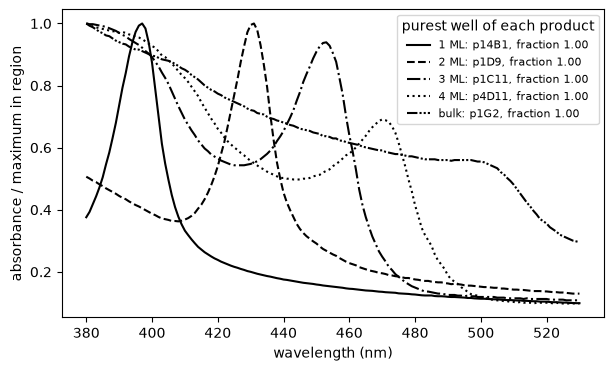

In [5]:
thickness_frac = pd.DataFrame({name: wells[col] for name, col in THICKNESS_FRACTIONS.items()})
fig, ax = plt.subplots(figsize=(7, 4))
for (name, style) in zip(THICKNESS_FRACTIONS, ["-", "--", "-.", ":", (0, (5, 1, 1, 1, 1, 1))]):
    i = wells.index.get_loc(thickness_frac[name].idxmax())
    y = absorbance[i, in_exc]
    ax.plot(wavelength[in_exc], y / y.max(), linestyle=style, color="black",
            label=f"{name}: {wells.index[i]}, fraction {thickness_frac[name].iloc[i]:.2f}")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("absorbance / maximum in region")
ax.legend(title="purest well of each product", fontsize=8)
plt.show()

*To write after running: one sentence on what the figure shows, with the wavelength of each exciton peak read from the plot. From the checks so far, expect peaks near 396 nm (1 ML), 427 to 431 nm (2 ML, the two references), 454 nm (3 ML), and 469 nm (4 ML), and for bulk CsPbBr₃ a band edge with no sharp peak.*

For 1 ML purest well (p14B1), the strongest peak is at 396nm with maximum absorbance of 1. 
For 2 ML purest well (p1D9, the two references), the strongest peak is at 430nm, with maximum absorbance of 1, but with a steeper negative slope to the left of the peak than to the right. 
For 3 ML purest well (p1C11), the strongest peak is at 454nm, with maximum absorbance of ~0.95, and lower rightward absorbances than 2 ML & larger leftward absorbances and steeper leftward slope than 2 ML which flattens to absorbance of 1 towards 380nm. 
For 4 ML purest well (p4D11), the strongest peak is at 469nm, with maximum absorbance of ~0.71, and lower rightward absorbances than 3 ML & larger leftward absorbances and steeper leftward slope than 3 ML which flattens to absorbance of 1 towards 380nm. 

### Concentrations and thickness counts

The first table gives the mean, median, and standard deviation of each concentration, over all 1351 wells and without the 15 low-volume p14 wells, whose stated values are wrong (problem 3). These concentrations were chosen by the experimenters on a grid, so the spread describes the design, not a measurement error. A mean far from the median marks a few plates set apart from the main grid. The second table counts the wells of each thickness, labelled as in the first analysis: the thickness product (1 to 4 ML or bulk) with the largest share of the deconvoluted absorbance, if that share is at least `PURITY_MIN`, otherwise `unlabelled`. Counts are given in total and per plate. Expect `[Br]` to have a mean below its median because of p8, and 2 ML to be the most common label. The last lines check whether any two plates have the same spectra, which the per-plate counts suggested: p7 and p8 have the same count in every column.

In [6]:
conc_stats = pd.concat({
    "all wells": wells[CONC_COLS].agg(["mean", "median", "std"]).T,
    "without low-volume p14": wells.loc[~low_volume, CONC_COLS].agg(["mean", "median", "std"]).T,
}, axis=1)
print("concentrations (mM):")
print(conc_stats.round(3).to_string())

explore_label = thickness_frac.idxmax(axis=1).where(thickness_frac.max(axis=1) >= PURITY_MIN, "unlabelled")
label_order = list(THICKNESS_FRACTIONS) + ["unlabelled"]
print(f"\nwells per thickness (PURITY_MIN {PURITY_MIN}):")
print(explore_label.value_counts().reindex(label_order, fill_value=0).to_string())
print("\nwells per thickness and plate:")
per_plate = pd.crosstab(wells.plate, explore_label).reindex(index=wells.plate.unique(), columns=label_order, fill_value=0)
print(per_plate.to_string())

spectrum_key = pd.Series([hash(row.tobytes()) for row in absorbance], index=wells.index)
duplicated = spectrum_key.duplicated(keep=False)
print(f"\nwells whose absorbance spectrum is identical to another well's: {int(duplicated.sum())}, "
      f"on plates {wells.plate[duplicated].value_counts().to_dict()}")
same_well = wells.index[wells.plate == "p7"].str[2:]
p7_abs = absorbance[wells.index.get_indexer("p7" + same_well)]
p8_abs = absorbance[wells.index.get_indexer("p8" + same_well)]
p7_em = emission[wells.index.get_indexer("p7" + same_well)]
p8_em = emission[wells.index.get_indexer("p8" + same_well)]
print(f"p7 against p8, same well: absorbance identical in {int((p7_abs == p8_abs).all(axis=1).sum())} of {len(same_well)}, "
      f"emission identical in {int(np.nan_to_num(p7_em == p8_em).all(axis=1).sum())}, "
      f"recipe identical in {int((wells.loc['p7' + same_well, VOLUME_COLS + ['Temp']].to_numpy() == wells.loc['p8' + same_well, VOLUME_COLS + ['Temp']].to_numpy()).all(axis=1).sum())}")

concentrations (mM):
      all wells                without low-volume p14               
           mean  median    std                   mean  median    std
[OLA]     2.786   2.432  0.946                  2.788   2.432  0.945
[Pb]      0.604   0.607  0.253                  0.606   0.607  0.252
[OA]      8.706   8.746  1.498                  8.724   8.872  1.490
[Cs]      0.350   0.300  0.190                  0.354   0.300  0.189
[Br]     11.889  12.720  3.018                 11.880  12.720  3.034

wells per thickness (PURITY_MIN 0.5):
1 ML          140
2 ML          388
3 ML          127
4 ML           51
bulk           31
unlabelled    614

wells per thickness and plate:
col_0  1 ML  2 ML  3 ML  4 ML  bulk  unlabelled
plate                                          
p0       16     7     0     0     0          60
p1        1    32    10     1     1          34
p2        0    66     4     2     0          24
p3        6    69     0     0     0          20
p4        0    12    20    14

The concentrations reflect the design. `[Pb]` has its mean (0.604 mM) at its median (0.607 mM). `[OLA]` and `[Cs]` have means above their medians (2.79 against 2.43 mM, 0.350 against 0.300 mM), from the plates that extend the grid to 4.86 mM OLA and 0.8 mM Cs. `[Br]` has its mean below its median (11.89 against 12.72 mM) because of the low-Br plate p8. Leaving out the 15 low-volume p14 wells moves no mean by more than 1%, so those wells matter for the conditions they cover (mostly Cs = 0 to 0.1 mM), not for these summaries. At `PURITY_MIN` 0.5, 737 of 1351 wells carry a thickness label: 388 are 2 ML, 140 are 1 ML, 127 are 3 ML, 51 are 4 ML, and 31 are bulk. The plates differ widely: p10, p14, and p15, with the lowest Cs, are mostly 1 ML, while p4 (40 °C) and p22 (highest Pb and Cs) hold most of the 4 ML and bulk wells.

**A problem found here.** p7 and p8 have the same count in every column because their absorbance spectra are identical, value for value, in all 96 wells, and so are the deconvolution fractions computed from them. Their recipes differ (p7 is at 50 °C with standard Br, p8 at 30 °C with one tenth of the Br), and so do their emission spectra. Both plates were run on 2019-07-25. One plate's absorbance appears to have been copied over the other's in the published file, and nothing in the file says which plate the spectra belong to.

## What the data can and cannot tell

The concentrations were set by a robot, so this is a designed experiment and not an observational one. That makes a causal reading stronger than it would be for survey data, but four features of the design still limit it. The cell below prints the number behind each.

1. **The five concentrations are not independent.** The lead and cesium solutions are oleates in oleic acid, so `[OA]` rises with the Pb and Cs volumes even when the OA volume is fixed. A fit of `[OA]` to the three volumes recovers that exactly. `[Pb]` and `[OA]` correlate at r ≈ 0.85, so an effect assigned to Pb may be an effect of OA, and the two can be separated only on the plates where the OA volume varies.
2. **Plate is confounded with temperature, stir rate, date, and stock solutions.** Each non-30 °C temperature is a single plate, and the stir rate changes with the plate, so a temperature effect cannot be told apart from a batch effect. Wells run under the same recipe on two or more plates show how large that batch effect is.
3. **Position within a plate follows the recipe.** The robot laid out the recipes in order, so on several plates the well row or column correlates strongly with a concentration. Any position effect, such as edge wells warming faster, mixing, or the order in which Br was injected, is mixed into the concentration effect.
4. **The product is read at one time, as an absorbance fraction.** The time between injection and reading is not in the file, and the article calls the reaction network weakly reversible, so a well's product may still have been changing. The thickness is a deconvolution result against 12 reference spectra (see item 1 of the problems).

These limits mean that "this concentration sets the thickness" is defensible only as "within these plates, at these times, changing this recipe parameter changed the absorbance-weighted product". The batch scatter in item 2 also caps how well any model can do on an unseen plate.

In [7]:
vol_design = np.column_stack([wells.OA, wells.Pb, wells.Cs, np.ones(len(wells))])
coef, *_ = np.linalg.lstsq(vol_design, wells["[OA]"], rcond=None)
resid = wells["[OA]"] - vol_design @ coef
print(f"1. [OA] = {coef[0]:.4f} OA + {coef[1]:.4f} Pb + {coef[2]:.4f} Cs + {coef[3]:.4f}  (mM per uL); largest residual {np.abs(resid).max():.1e} mM")
print(f"   plates on which the OA volume varies: {wells.groupby('plate', sort=False).OA.nunique()[lambda s: s > 1].index.tolist()}")
print(wells[CONC_COLS].corr().round(2).to_string())

recipe = wells[CONC_COLS + ["Temp"]].round(4).astype(str).agg("|".join, axis=1)
dominant = thickness_frac.idxmax(axis=1).where(thickness_frac.max(axis=1) >= PURITY_MIN, "mixed or other")
shared = wells.groupby(recipe).plate.nunique()[lambda s: s > 1].index
agree = dominant[recipe.isin(shared)].groupby(recipe[recipe.isin(shared)]).nunique()
print(f"\n2. recipes run on more than one plate: {len(shared)}; the same dominant product (PURITY_MIN {PURITY_MIN}) on every plate: {int((agree == 1).sum())}")
print(f"   temperature per plate: {wells.groupby('Temp').plate.unique().apply(list).to_dict()}")
print(f"   stir rate per plate:   {wells.groupby('stir_rpm').plate.unique().apply(list).to_dict()}")

row_num = wells.well_row.map("ABCDEFGH".index)
position = pd.DataFrame({p: {f"{axis} vs {c}": (row_num if axis == "row" else wells.well_col)[g.index].corr(g[c])
                             for axis in ["row", "col"] for c in ["[Pb]", "[Cs]", "[OLA]"]}
                         for p, g in wells.groupby("plate", sort=False)}).T
print("\n3. correlation of well position with concentration, plates with any |r| > 0.6:")
print(position[(position.abs() > 0.6).any(axis=1)].round(2).to_string())

1. [OA] = 0.0794 OA + 0.0316 Pb + 0.0316 Cs + 0.0000  (mM per uL); largest residual 1.6e-14 mM
   plates on which the OA volume varies: ['p3', 'p10', 'p15']
       [OLA]  [Pb]  [OA]  [Cs]  [Br]
[OLA]   1.00 -0.03 -0.01 -0.02  0.01
[Pb]   -0.03  1.00  0.85  0.06  0.02
[OA]   -0.01  0.85  1.00  0.46  0.03
[Cs]   -0.02  0.06  0.46  1.00  0.07
[Br]    0.01  0.02  0.03  0.07  1.00

2. recipes run on more than one plate: 56; the same dominant product (PURITY_MIN 0.5) on every plate: 33
   temperature per plate: {30: ['p0', 'p1', 'p2', 'p3', 'p6', 'p8', 'p9', 'p10', 'p14', 'p15', 'p21', 'p22'], 35: ['p5'], 40: ['p4'], 50: ['p7']}
   stir rate per plate:   {400: ['p5', 'p6', 'p7', 'p8', 'p9', 'p10', 'p14', 'p15', 'p21', 'p22'], 600: ['p1', 'p2', 'p3', 'p4'], 800: ['p0']}

3. correlation of well position with concentration, plates with any |r| > 0.6:
     row vs [Pb]  row vs [Cs]  row vs [OLA]  col vs [Pb]  col vs [Cs]  col vs [OLA]
p1          0.39         0.74          0.08         0.14      

## How exploration changed the analysis plan

The plan in the topic declaration was to relate thickness to the five concentrations over all wells, and to test a model on held-out plates. Seven findings above change how that is done.

1. **The plates are not repeats of one design** (Exploration table). Br varies only on p0 and p8, each temperature other than 30 °C is a single plate, and Cs = 0 occurs only on p14, p15, p21, and p22. Pooling every well would mix temperature and Br effects, which cannot be separated from plate effects, into the effects of `[Pb]`, `[Cs]`, and `[OLA]`. *Change:* the first analysis uses a base set at `BASE_TEMP` and `BASE_BR`, and in the whole-plate test the plates p4, p5, p7, and p8 count as extrapolation, reported separately.
2. **15 wells of p14 have wrong concentrations** (problem 3). *Change:* they are left out of the base set until decision (c) is made, and comparing them with the same recipes on p15, the repeat plate, is a check in that decision.
3. **`[OA]` is set by the Pb and Cs volumes** (What the data can and cannot tell, item 1). A `[Pb]` effect and an `[OA]` effect cannot be told apart. *Change:* the matched steps hold the OA volume fixed, the `[Pb]` result is stated as a lead oleate effect, and the model has to use inputs that are not exact combinations of one another, such as the five volumes or ratios like `[Cs]/[Pb]`.
4. **Repeats on different plates often disagree** (item 2). Only 33 of the 56 recipes run on more than one plate give the same dominant product on each. *Change:* concentration effects are measured within a plate (the matched steps), not by pooling plates. That agreement rate is also the most a whole-plate model can be expected to reach, and the model's score is compared with it.
5. **Well position follows the recipe** (item 3). *Change:* a check for edge-well effects is added to Checking the assumptions.
6. **About half of the wells hold no platelet thickness** (thickness counts above). Most unlabelled wells are dominated by non-platelet species such as PbBr₃⁻ or Cs₄PbBr₆, not by mixed thicknesses. *Change:* the thickness question is answered for the wells that make platelets, and the model must either predict "no platelet" as its own class or be preceded by a step that predicts whether a recipe makes platelets at all.
7. **p7 and p8 share one set of absorbance spectra** (Concentrations and thickness counts). For at least one of these plates, the thickness labels belong to a different recipe. *Change, TO DECIDE:* leave both plates out of every absorbance-based result (thickness labels, the model, the exciton energies), or keep the plate the spectra are shown to belong to. Each plate's emission spectra, which are not duplicated, can be the test. Neither plate is in the base set (p7 is at 50 °C and p8 is at low Br), so the first analysis is unaffected. The whole-plate test is affected, since leaving p7 or p8 out would leave its duplicate in the training data.

## First analysis: the thickness of each synthesis, and which concentrations set it

**Plan.** Label each well with its dominant product from `THICKNESS_FRACTIONS` (1 to 4 ML or bulk) when that product holds at least `PURITY_MIN` of the deconvoluted absorbance, and "mixed or other" otherwise. Before using the labels, decide three things. (a) `PURITY_MIN`: count the labels at 0.3, 0.5, and 0.7 (the checks gave 921, 737, and 422 labelled wells) and see which conclusions change. (b) `MIN_R2`: list what the 78 poorly fitted wells are, since most are 1 ML or PbBr₃⁻ wells, which may be a real limit of the references rather than bad data. (c) What to do with the 15 low-volume p14 wells and the 11 reference wells. Then show how the label changes with each concentration. One option is the authors' layout: maps of the label over `[Pb]` and `[Cs]` at each `[OLA]` at 30 °C and fixed Br. Another is a single-variable trend at fixed others, using the 2 ML / 3 ML boundary as the readout. A numeric alternative to the label is the absorbance-weighted mean thickness, Σ n·fₙ / Σ fₙ, which keeps the information in mixed wells.

**Check against the chemistry.** More Cs per Pb should give thicker plates, since each extra layer needs one more layer of Cs. More OLA should give thinner ones, since the amine caps the plate surfaces. If the maps disagree, look at the raw spectra of a few wells before trusting the deconvolution.

**What the cells below do.** The analysis uses the *base set*: wells at `BASE_TEMP` and `BASE_BR`, without the 15 low-volume p14 wells (decision (c), proposed), so that `[Pb]`, `[Cs]`, and `[OLA]` are the only recipe variables besides the OA volume. The first cell labels every well, counts the labels at each of `PURITY_LEVELS`, and says what the unlabelled wells hold instead. Expect about half of the base set to be unlabelled at 0.5, mostly wells whose largest component is not a platelet at all.

In [8]:
def label_wells(purity_min):
    """Dominant thickness product of each well, or 'unlabelled' when no product holds purity_min of the absorbance."""
    return thickness_frac.idxmax(axis=1).where(thickness_frac.max(axis=1) >= purity_min, "unlabelled")


base = (wells.Temp == BASE_TEMP) & np.isclose(wells["[Br]"], BASE_BR) & ~low_volume
wells["thickness"] = label_wells(PURITY_MIN)
wells["thickness_share"] = thickness_frac.max(axis=1)  # share of absorbance held by the dominant product
print(f"base set: {int(base.sum())} of {len(wells)} wells on plates {wells.plate[base].unique().tolist()}")

label_names = list(THICKNESS_ORDER) + ["unlabelled"]
counts = pd.DataFrame({f"purity {p}": label_wells(p)[base].value_counts() for p in PURITY_LEVELS}).reindex(label_names).fillna(0).astype(int)
print("\nlabels in the base set:")
print(counts.to_string())

components = wells.filter(regex=r"^f(?!t)").drop(columns=["f1 ML", "f1 ML_2", "f2 ML", "f2 ML_2"])
components = components.assign(**{"f1 ML": wells["ft1 ML"], "f2 ML": wells["ft2 ML"]})  # 12 components with the two 1 ML and two 2 ML references summed
unlabelled = base & (wells.thickness == "unlabelled")
print(f"\nunlabelled at purity {PURITY_MIN}: {int(unlabelled.sum())} wells; their largest component:")
print(components[unlabelled].idxmax(axis=1).value_counts().to_string())
low_r2 = base & (wells.thickness != "unlabelled") & (wells["Deconvolution R^2"] < MIN_R2)
print(f"\nlabelled wells with R^2 below {MIN_R2}: {int(low_r2.sum())}, {wells.thickness[low_r2].value_counts().to_dict()}")

base set: 915 of 1351 wells on plates ['p0', 'p1', 'p2', 'p3', 'p6', 'p9', 'p10', 'p14', 'p15', 'p21', 'p22']

labels in the base set:
            purity 0.3  purity 0.5  purity 0.7
1 ML               131         103          55
2 ML               287         247         162
3 ML               106          82          52
4 ML                39          26          14
bulk                28          20          10
unlabelled         324         437         622

unlabelled at purity 0.5: 437 wells; their largest component:
fPbBr3-      123
fPbBr2        60
fCs4PbBr6     59
fbg           59
fCsPb2Br5     51
f2 ML         36
f1 ML         19
f3 ML         19
f4 ML          7
fCsPbBr3       4

labelled wells with R^2 below 0.9: 36, {'1 ML': 22, '2 ML': 10, '3 ML': 4}


In the base set of 915 wells, purity 0.5 labels 478 wells, and 2 ML is the most common product (247 wells), followed by 1 ML (103) and 3 ML (82). The 437 unlabelled wells are mostly not mixed platelets. In 352 of them the largest component is not a platelet at all (PbBr₃⁻ 123, PbBr₂ 60, Cs₄PbBr₆ 59, background 59, CsPb₂Br₅ 51), and only 85 are platelet wells in which no single thickness reaches 0.5. Of the labelled wells, 36 have a deconvolution R² below `MIN_R2`, 22 of them 1 ML, so the 1 ML labels are the least certain.

### Thickness distributions over `[Pb]`, `[Cs]`, and `[OLA]`

For each concentration, the figure shows the share of each label among the base-set wells at every level of that concentration, pooled over the other two. Only levels with at least `MIN_WELLS_PER_LEVEL` wells are drawn; the levels with fewer belong to the fine transition grids of p2 and p6. The labels use `PURITY_MIN`. Each label has its own gray level and hatching, so that no meaning is carried by color alone. Pooling mixes the effect of one concentration with the spread of the other two, so this figure shows the distributions, and the matched steps in the next cell measure the effect.

Expect thicker labels at higher `[Cs]`, thinner labels at higher `[OLA]`, and a weaker trend with `[Pb]`, which also brings OA and moves the Cs to Pb ratio.

[Pb]: 842 of 915 base wells at levels drawn
[Cs]: 823 of 915 base wells at levels drawn
[OLA]: 900 of 915 base wells at levels drawn


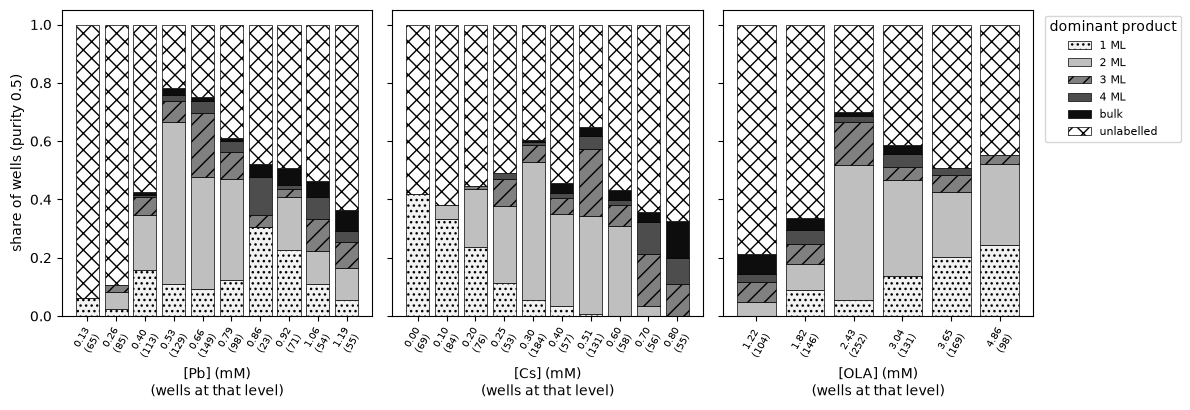

In [9]:
label_style = {  # label: (face gray, hatch), from thin to thick, then unlabelled
    "1 ML": ("0.95", "..."), "2 ML": ("0.75", ""), "3 ML": ("0.5", "//"), "4 ML": ("0.3", ""),
    "bulk": ("0.05", ""), "unlabelled": ("white", "xx"),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
for ax, conc in zip(axes, ["[Pb]", "[Cs]", "[OLA]"]):
    level = wells.loc[base, conc].round(3)
    keep = level.groupby(level).transform("size") >= MIN_WELLS_PER_LEVEL
    share = pd.crosstab(level[keep], wells.thickness[base][keep], normalize="index").reindex(columns=label_names, fill_value=0)
    n_wells = level[keep].value_counts().sort_index()
    x = np.arange(len(share))
    bottom = np.zeros(len(share))
    for name in label_names:
        face, hatch = label_style[name]
        ax.bar(x, share[name], bottom=bottom, color=face, hatch=hatch, edgecolor="black", linewidth=0.5, label=name)
        bottom += share[name].to_numpy()
    ax.set_xticks(x, [f"{v:.2f}\n({n})" for v, n in zip(share.index, n_wells)], fontsize=7, rotation=60)
    ax.set_xlabel(f"{conc} (mM)\n(wells at that level)")
    print(f"{conc}: {int(keep.sum())} of {int(base.sum())} base wells at levels drawn")
axes[0].set_ylabel(f"share of wells (purity {PURITY_MIN})")
axes[-1].legend(title="dominant product", fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

The figure shows that raising `[Cs]` moves the labelled wells from 1 ML (42% of wells at 0 mM) through 2 ML (47% at 0.30 mM) to 3 ML, 4 ML, and bulk (together 33% at 0.80 mM), that raising `[OLA]` raises the share of 1 ML from 6% at 2.43 mM to 24% at 4.86 mM, and that `[Pb]` below 0.3 mM leaves about 90% of wells unlabelled, while above it the trend is irregular.

### How the thickness changes when one concentration changes

The figure pools wells whose other concentrations differ. A cleaner comparison uses wells on the **same plate** whose recipes differ in **one** concentration only, at the same OA volume. Within each such series, the cell steps from each level of the concentration to the next higher one and compares the median thickness rank (`THICKNESS_ORDER`, with replicates pooled) of the two levels: thicker, the same, or thinner. Holding the plate fixed removes the batch effect, and holding the OA volume fixed keeps the plates where OA varies (p3, p10, p15) from mixing in an OA effect. Raising `[Pb]` still raises `[OA]` through the lead oleate solution, so a `[Pb]` step is a step in both. Unlabelled wells are left out of the comparison, so each purity level compares a different set of wells. Expect one row per concentration and purity, with the number of steps and the share that go thicker, stay, or go thinner.

In [10]:
def matched_steps(purity_min):
    rank = label_wells(purity_min).map(THICKNESS_ORDER)  # NaN for unlabelled
    d = wells[base].assign(rank=rank[base]).dropna(subset=["rank"])
    out = []
    for conc in ["[Pb]", "[Cs]", "[OLA]"]:
        held = ["plate", "OA"] + [c for c in ["[Pb]", "[Cs]", "[OLA]"] if c != conc]
        signs = []
        for _, series in d.groupby(held):
            by_level = series.groupby(series[conc].round(3))["rank"].median().sort_index()
            signs += list(np.sign(np.diff(by_level.to_numpy())))
        signs = np.array(signs)
        out.append({"concentration": conc, "purity": purity_min, "steps": signs.size,
                    "thicker": (signs > 0).mean(), "same": (signs == 0).mean(), "thinner": (signs < 0).mean()})
    return out


steps = pd.DataFrame([row for p in PURITY_LEVELS for row in matched_steps(p)])
print(steps.sort_values(["concentration", "purity"]).to_string(index=False, formatters={
    "thicker": "{:.2f}".format, "same": "{:.2f}".format, "thinner": "{:.2f}".format}))

concentration  purity  steps thicker same thinner
         [Cs]     0.3    208    0.25 0.72    0.02
         [Cs]     0.5    158    0.22 0.76    0.02
         [Cs]     0.7     76    0.16 0.84    0.00
        [OLA]     0.3    197    0.01 0.59    0.40
        [OLA]     0.5    140    0.01 0.62    0.37
        [OLA]     0.7     63    0.00 0.63    0.37
         [Pb]     0.3    230    0.20 0.78    0.02
         [Pb]     0.5    167    0.16 0.83    0.01
         [Pb]     0.7     87    0.09 0.91    0.00


**How the thickness changes.** At purity 0.5, one step up in `[Cs]` on the same plate makes the product thicker in 22% of 158 steps and thinner in 2%. One step up in `[OLA]` makes it thinner in 37% of 140 steps and thicker in 1%. One step up in `[Pb]` makes it thicker in 16% of 167 steps and thinner in 1%. Most steps (62 to 83%) leave the label unchanged, because a single step crosses a thickness boundary only near that boundary. The direction of each concentration is nearly one-sided, however: Cs and Pb thicken, OLA thins. Both directions agree with the chemistry in the plan. Each added layer needs Cs between the lead bromide sheets, and with no Cs (0 mM) every labelled well is 1 ML, OLA₂PbBr₄, which has no Cs. OLA caps the plate surfaces, so more of it stops growth sooner. The `[Pb]` effect cannot be told apart from an OA effect, since lead oleate raises `[OA]` too, and pooled over the other concentrations (figure) it is not monotonic.

**How the purity standard affects the result.** Raising the cutoff from 0.3 to 0.5 to 0.7 drops the labelled wells in the base set from 591 to 478 to 293. The direction of every effect stays the same at all three levels. Its size shrinks for Cs (thicker in 25%, 22%, then 16% of steps) and for Pb (20%, 16%, then 9%), while for OLA it stays near 37 to 40%. The shrinkage follows from what a high cutoff removes. A well near a boundary between two thicknesses holds both, so it falls below the cutoff, and the steps that cross a boundary are the ones left out. At 0.5 most unlabelled wells are non-platelet products, which no cutoff would label, so 0.5 mainly removes the 85 mixed platelet wells. The conclusions about direction therefore do not depend on the choice of 0.5, but the shares of steps that change thickness do, and they are lower bounds at 0.7.

## Final analysis: a model tested on whole plates it has never seen

**Plan.** Predict the thickness (the label, or the mean thickness) from the five concentrations and the temperature, with a model from `scikit-learn`, for example multinomial logistic regression with ratios such as `[Cs]/[Pb]` and `[OLA]/[Pb]` as inputs, or a random forest. Test it by leave-one-plate-out cross-validation (`LeaveOneGroupOut` with `plate` as the group), never by a random split of wells. Neighbouring wells on one plate share a batch, and a random split would let the model learn that batch and overstate its accuracy. Compare against two baselines: always predicting the most common label, and a model scored by a random split of wells. The gap between the random-split score and the whole-plate score is the batch effect. Report the score of each held-out plate separately. A plate whose conditions lie outside every other plate (p8 for Br, p7 for 50 °C, p21 and p22 for the highest Pb and Cs) tests extrapolation, not interpolation, and should be discussed as such.

Expect one score per held-out plate, the two baselines, and a confusion matrix.

In [11]:
# To write: features, model, LeaveOneGroupOut by plate, per-plate scores, baselines, confusion matrix

## Exciton energy against thickness

**Plan.** For each well labelled 1 to 4 ML, find the wavelength of the absorbance maximum in a window around that thickness's exciton, set in Parameters from the figure in Exploration, and convert it to energy as `HC / wavelength` (eV). Plot the energy against the number of layers n with the spread over wells, and compare it with a quantum-confinement form, such as E(n) = E_bulk + A / n² or the dielectric-confinement form used in the literature. Fit it with `scipy.optimize.curve_fit` and check the residuals. Two points to address: 2 ML has two reference spectra about 4 nm apart (427 and 431 nm), so decide whether these are one thickness with two lateral sizes or two populations, and bulk CsPbBr₃ shows a band edge, not a peak, so it needs its own definition (for example, the half-height of the edge) or is left out of the fit.

**Check against the chemistry.** The energy should fall with n and approach the bulk band gap of CsPbBr₃, about 2.4 eV (about 515 nm), at large n. A peak outside its window or an energy that rises with n points to a wrong label.

Expect one energy and spread per thickness, the fitted parameters, and a figure.

In [12]:
# To write: peak wavelength per labelled well, energy in eV, energy against n with a confinement fit and its residuals

## Checking the assumptions

**Plan.** Each item tests something the results above rest on.
1. **The labels do not depend on the thresholds.** Rerun the conclusions of the first analysis at the other values of `PURITY_MIN` and `MIN_R2`.
2. **The batch effect.** For recipes run on two or more plates, measure how often the label agrees, and compare that with the whole-plate model score. A model cannot be more consistent than the experiment's own repeats.
3. **Position effects.** Within plates whose recipes do not follow the layout, test whether edge wells differ from centre wells.
4. **The OA and Pb confound.** On the plates where the OA volume varies (p3, p10, p15), test whether the trend assigned to Pb holds at fixed `[OA]`.
5. **The absorbance range.** Repeat the exciton fit without wells above `OD_LINEAR_MAX`.

Expect one line of numbers per item.

In [13]:
# To write: one check per item above

## Result

*To write when the analyses are done: the answer to each of the three parts of the question with its number and uncertainty, how the chemistry agrees or disagrees, and the limits, including those in "What the data can and cannot tell".*

## Visual summary

*To write: one page in `output/summary.pdf` with the question, the finding and its uncertainty, three figures each with one sentence (a thickness map, the per-plate model scores, and the exciton energy against thickness), and the data source, with one marker or line style per series.*

In [14]:
# To write: the summary page, saved to output/summary.pdf

The last cell prints the software versions.

In [15]:
print(f"Python       {sys.version.split()[0]}")
print(f"NumPy        {np.__version__}")
print(f"pandas       {pd.__version__}")
print(f"SciPy        {scipy.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"Matplotlib   {matplotlib.__version__}")

Python       3.14.8
NumPy        2.5.3
pandas       3.0.6
SciPy        1.18.1
scikit-learn 1.9.1
Matplotlib   3.11.2
